# Student Details
## Name: Neeraj R Rugi
## SRN: PES2UG24CS311

# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Practical Notebook: Reviewing a Parking-Lot Event

### Background

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Complete the sections identified by **`# TODO`**. Add your own explanations in each **Reflection** section.

## Part 0 — Setup (given)

Execute this supplied cell without changes. It imports the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — Estimating the Storage Requirement (Request #1)

**Practical context:** These calculations provide a first estimate for planning storage across a multi-camera installation.

**Concept being applied:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**Tasks to complete:**
1. Calculate the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Calculate the number of frames ONE camera records in 24 h at 30 fps.
3. Calculate the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Calculate the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# One 1080p RGB frame: 3 channels at one byte per channel.
frame_bytes = 1920 * 1080 * 3 * 1
frame_mb = frame_bytes / 1024**2

# Frames recorded by one camera in 24 hours at 30 fps.
frames_per_day = 30 * 24 * 60 * 60

# Fleet storage in binary terabytes.
fleet_tb = frame_bytes * frames_per_day * 400 / 1024**4

small_frame_bytes = 640 * 360 * 3
fleet_tb_small = small_frame_bytes * (10 * 24 * 60 * 60) * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")


One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Think about and explain:** Downsampling loses **spatial evidence** such as a small face, license-plate character, or a distant object whose detail is below the 360p pixel size. It also loses **temporal evidence**: reducing 30 fps to 10 fps can miss a brief action or create correspondence ambiguity when an object moves between the retained frames.


## Task 2 — Assessing and Improving a Low-Light Image (Request #2)

**Practical context:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Concept being applied:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**Tasks to complete:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) next to one another.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Create a plot of the stretched image + histogram, and print the new contrast.

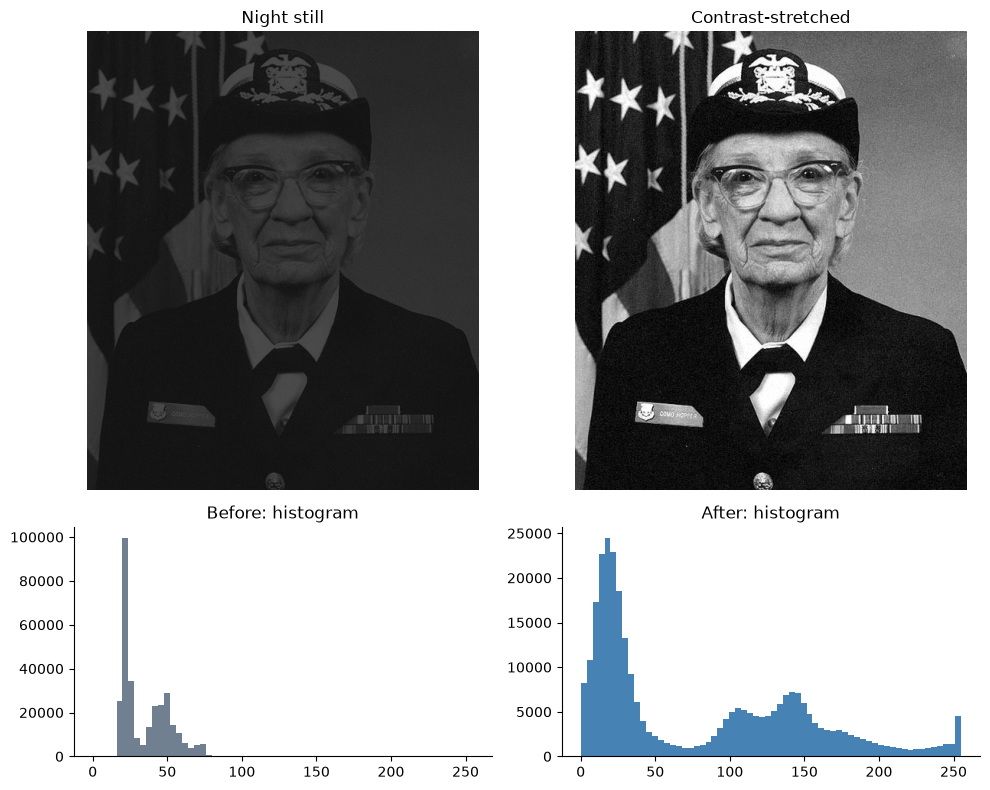

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)
c_after = michelson(*np.percentile(stretched, [99, 1]))

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
axes[0, 0].imshow(night_still, cmap="gray", vmin=0, vmax=255); axes[0, 0].set_title("Night still")
axes[1, 0].hist(night_still.ravel(), bins=64, range=(0, 255), color="slategray"); axes[1, 0].set_title("Before: histogram")
axes[0, 1].imshow(stretched, cmap="gray", vmin=0, vmax=255); axes[0, 1].set_title("Contrast-stretched")
axes[1, 1].hist(stretched.ravel(), bins=64, range=(0, 255), color="steelblue"); axes[1, 1].set_title("After: histogram")
for ax in axes.flat[:2]: ax.axis("off")
plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")


**Think about and explain:** The histogram is narrow and concentrated toward the dark end, so it is a low-contrast, underexposed distribution rather than a well-spread range. Stretching remaps the existing intensity values across the display range, making differences visible without recovering detail or adding information. A histogram has no spatial arrangement, so different images can share the same histogram while containing completely different objects (?Same Histogram ? Same Image?).


## Task 3 — Summarising the Footage with an Event Timeline (Request #3)

**Practical context:** Security staff usually need to locate significant moments quickly instead of watching the complete recording from beginning to end.

**Concept being applied:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**Tasks to complete:**
1. Calculate the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Determine the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing: 68.7?78.1 s
Running: 78.6?86.0 s


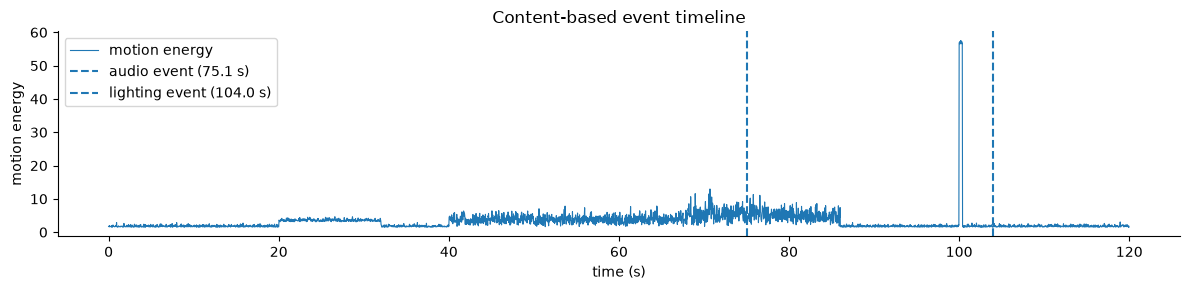

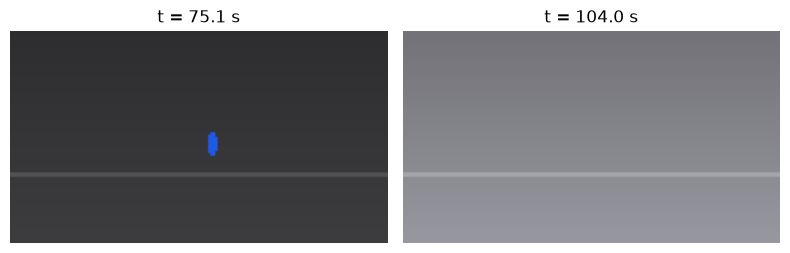

In [4]:
# A one-second displacement is more robust to frame-to-frame tracking jitter.
speed = np.hypot(cctv.person_x - cctv.person_x.shift(FPS),
                 cctv.person_y - cctv.person_y.shift(FPS)) / 1.0

def print_ranges(mask, label):
    idx = np.flatnonzero(mask.fillna(False).to_numpy())
    if len(idx): print(f"{label}: {cctv.time_s.iloc[idx[0]]:.1f}?{cctv.time_s.iloc[idx[-1]]:.1f} s")
    else: print(f"{label}: none")

print_ranges(speed < 3, "Standing")
print_ranges(speed > 25, "Running")

# Audio spike near 75 s and the sustained lighting change near 100 s.
audio_event_idx = int(cctv.audio_level_db.to_numpy().argmax())
lighting_event_idx = int(cctv.mean_brightness.to_numpy().argmax())

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, label="motion energy")
for i, label in [(audio_event_idx, "audio event"), (lighting_event_idx, "lighting event")]:
    ax.axvline(cctv.time_s.iloc[i], ls="--", label=f"{label} ({cctv.time_s.iloc[i]:.1f} s)")
ax.set(xlabel="time (s)", ylabel="motion energy", title="Content-based event timeline"); ax.legend()
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for ax, i in zip(axes, [audio_event_idx, lighting_event_idx]):
    ax.imshow(render_frame(cctv.iloc[i])); ax.set_title(f"t = {cctv.time_s.iloc[i]:.1f} s"); ax.axis("off")
plt.tight_layout(); plt.show()


**Think about and explain:** Uniform keyframes every 20 s would probably miss the short acoustic event around 75 s and could miss the onset of the lighting change around 100 s because neither is guaranteed to fall on a sampling instant. The approach used here is **content-based keyframe extraction/event-driven summarization**: select frames where the signals indicate meaningful change.


## Task 4 — Classifying the Acoustic Event (Request #4)

**Practical context:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Concept being applied:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**Tasks to complete:**
1. Create a plot of the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Create a plot of their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

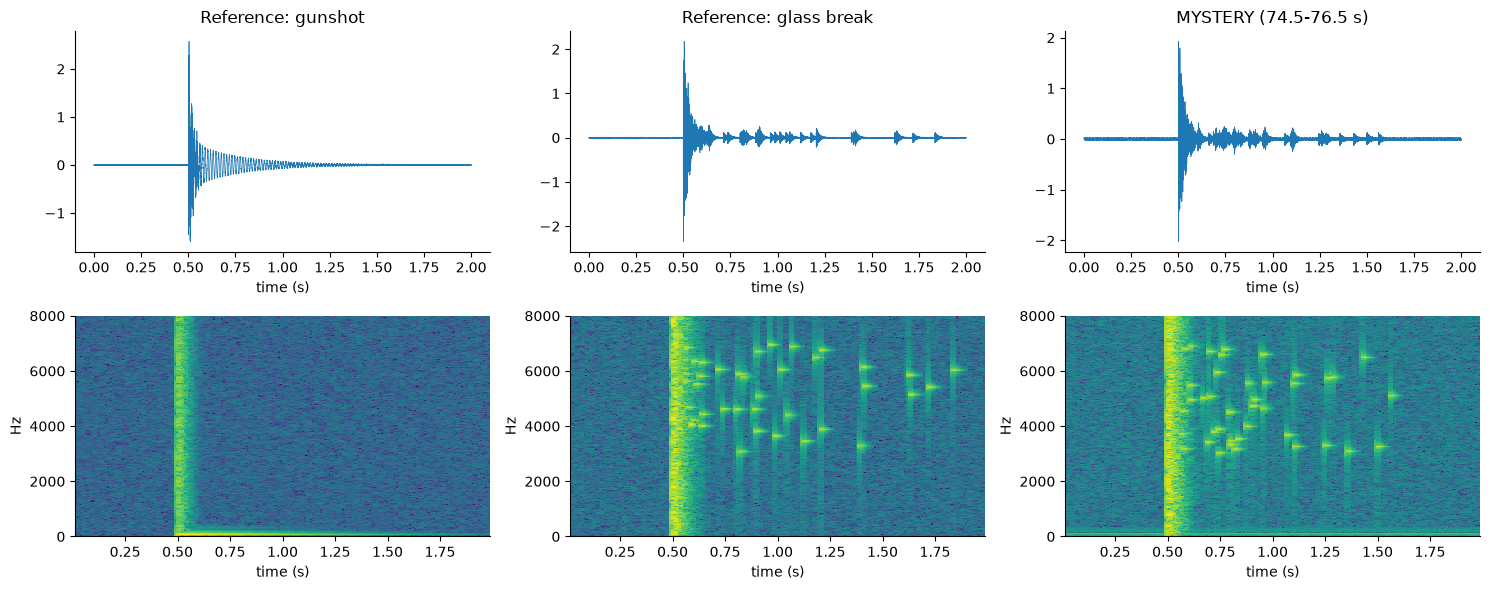

{'Reference: gunshot': np.float64(0.21536812880335365), 'Reference: glass break': np.float64(0.6377676959141665), 'MYSTERY (74.5-76.5 s)': np.float64(0.6562646133216413)}
Verdict: the mystery sound is most consistent with a glass break.


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
hf_fraction = {}
for col, (name, clip) in enumerate(clips.items()):
    tt = np.arange(len(clip)) / FS
    axes[0, col].plot(tt, clip, lw=0.5); axes[0, col].set_title(name); axes[0, col].set_xlabel("time (s)")
    f, st, S = signal.spectrogram(clip, fs=FS, nperseg=512, noverlap=384)
    keep = st >= 0.2; S_db = 10 * np.log10(S + 1e-12)
    axes[1, col].pcolormesh(st, f, S_db, shading="auto"); axes[1, col].set_ylim(0, 8000); axes[1, col].set_xlabel("time (s)"); axes[1, col].set_ylabel("Hz")
    band = (st >= 0.2) & (st <= 1.2)
    total = S[:, band].sum(); hf_fraction[name] = S[(f > 3000), :][:, band].sum() / total

plt.tight_layout(); plt.show()
print(hf_fraction)
verdict = "glass break" if hf_fraction["MYSTERY (74.5-76.5 s)"] > hf_fraction["Reference: gunshot"] else "gunshot"
print(f"Verdict: the mystery sound is most consistent with a {verdict}.")


**Think about and explain:** The waveforms show that both events are short, noisy impacts, so timing and amplitude alone would not support a confident classification. A spectrogram adds **time, frequency and magnitude**; the mystery?s lingering scattered high-frequency specks match the glass reference rather than the gunshot?s concentrated transient/low-frequency decay.


## Task 5 — Combining the Evidence in One Briefing View (Request #5)

**Practical context:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Concept being applied:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**Tasks to complete:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) using an identical time marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

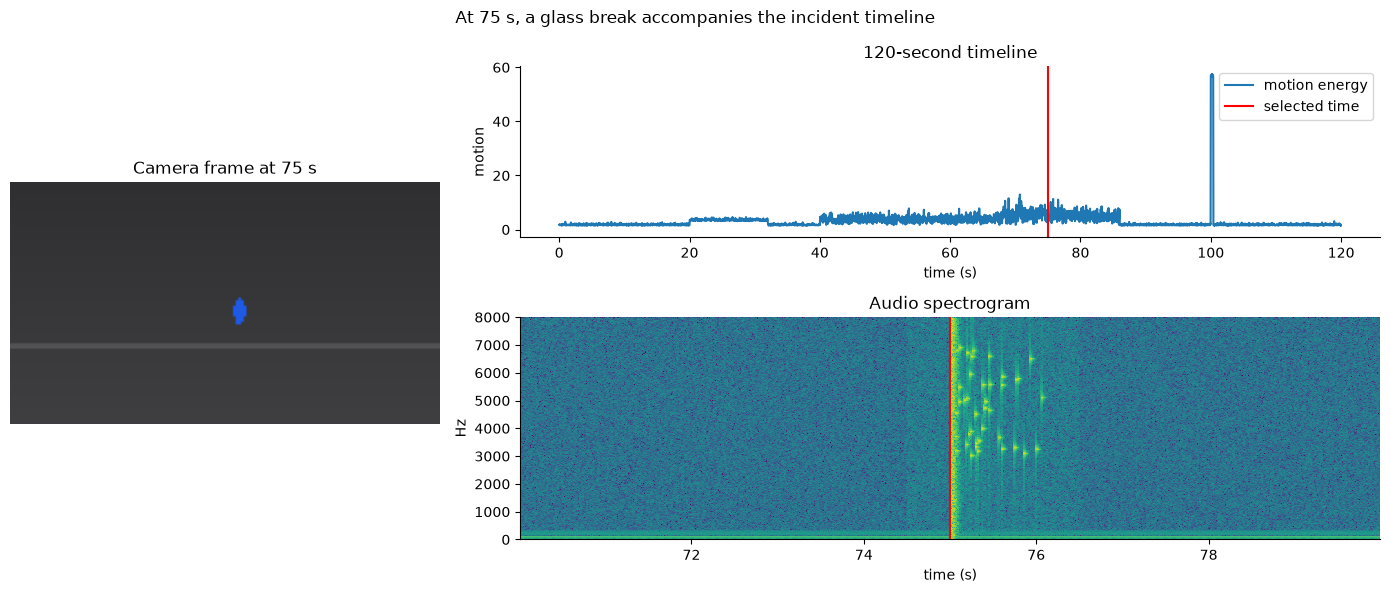

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
ax_frame = fig.add_subplot(gs[:, 0]); ax_motion = fig.add_subplot(gs[0, 1]); ax_spec = fig.add_subplot(gs[1, 1])
frame_idx = int(np.abs(cctv.time_s - t_sel).argmin())
ax_frame.imshow(render_frame(cctv.iloc[frame_idx])); ax_frame.axis("off"); ax_frame.set_title(f"Camera frame at {t_sel:.0f} s")
ax_motion.plot(cctv.time_s, cctv.motion_energy, label="motion energy")
ax_motion.plot(t_audio, np.interp(t_audio, [t_audio.min(), t_audio.max()], [0, 1]), alpha=0)
ax_motion.axvline(t_sel, color="red", label="selected time"); ax_motion.set(xlabel="time (s)", ylabel="motion", title="120-second timeline"); ax_motion.legend()
f, st, S = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_spec.pcolormesh(t_audio[0] + st, f, 10 * np.log10(S + 1e-12), shading="auto"); ax_spec.set_ylim(0, 8000)
ax_spec.axvline(t_sel, color="red"); ax_spec.set(xlabel="time (s)", ylabel="Hz", title="Audio spectrogram")
fig.suptitle("At 75 s, a glass break accompanies the incident timeline")
plt.tight_layout(); plt.show()


**Think about and explain:** The +2s offset would cause a delay in the audio and would lead to incorrect association of the audio with the visual. This would be highlighted by looking at the time synced spectrogram panel. The 75s red marker would no longer match up with the audio burst. The frame panel would also show an incorrect scene.


**Your final briefing here:** Lot B’s camera captures the incident around 75s, and the audio matches most with the impact of glass shattering. At ~100s there is a change in lighting. The synchronised data would be presented first as it provides an overview of what is happening in the video, and how it relates back to the chosen moment in time. This also shows that there is a key frame that can be related to the time-frequency-magnitude data on the spectrogram. As the key frames are content based rather than being sampled regularly, they are more useful. If we were to keep recording at 1080p/30fps, then we would need around 2905.6TB per day for 400 cameras. It would be best to keep recording at 640-360 at 10fps for regular storage. We need to ensure that we do not lose any of the short audio/video evidence when recording our policy. The temporal information will help us determine that the glass was shattered.
